In [1]:
import os
os.makedirs("data", exist_ok=True)
os.makedirs("img", exist_ok=True)

In [2]:
import numpy as np
import pandas as pd
import os

os.makedirs("data", exist_ok=True)  
os.makedirs("img", exist_ok=True)    

rng = np.random.default_rng(2026)
N = 200


In [3]:
import os
print(os.getcwd())

C:\Users\user


In [4]:
import numpy as np
import pandas as pd

rng = np.random.default_rng(2026)
N = 200

discipline = rng.normal(0, 1, N)

study      = np.clip(rng.normal(3, 1, N) + 0.8 * discipline, 0, 8)     
sleep      = np.clip(rng.normal(6.5, 1, N) + 0.3 * discipline, 4, 9)  
attendance = np.clip(rng.normal(75, 8, N) + 6 * discipline, 40, 100) 
screen     = np.clip(rng.normal(5, 1.5, N) - 0.5 * discipline, 1, 10) 

marks = (30 + 4 * study + 0.25 * attendance
         + 1.5 * sleep - 0.8 * screen + rng.normal(0, 6, N))
marks = np.round(np.clip(marks, 0, 100), 1)

W = {"study": 0.4, "attendance": 0.3, "sleep": 0.3}
s_study = np.clip(study / 6, 0, 1) * 100
s_sleep = np.clip((sleep - 4) / 4, 0, 1) * 100
habit = W["study"] * s_study + W["attendance"] * attendance + W["sleep"] * s_sleep

df = pd.DataFrame({
    "student_id": [f"S{100 + i}" for i in range(N)],
    "study_hours": np.round(study, 1),
    "sleep_hours": np.round(sleep, 1),
    "attendance_pct": np.round(attendance, 1),
    "screen_hours": np.round(screen, 1),
    "habit_score": np.round(habit, 1),
    "marks": marks,
})
df.to_csv("data/students.csv", index=False)

print(f"generated {len(df)} students -> data/students.csv")
print(df.describe().loc[["mean", "std", "min", "max"]].round(2).to_string())

generated 200 students -> data/students.csv
      study_hours  sleep_hours  attendance_pct  screen_hours  habit_score  marks
mean         3.09         6.54           75.77          4.88        62.09  66.56
std          1.32         1.07            9.91          1.66        13.85   9.35
min          0.00         4.00           41.70          1.00        24.90  43.90
max          6.20         9.00           99.60          9.00        98.40  86.30


In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("data/students.csv")

print("1. PROFILE")
print(f"students {len(df)}  mean marks {df.marks.mean():.1f}  "
      f"mean sleep {df.sleep_hours.mean():.2f} h")
print(f"sleeping under 6 h: {(df.sleep_hours < 6).mean() * 100:.1f}%")

print("\n2. CORRELATION WITH MARKS")
cols = ["study_hours", "sleep_hours", "attendance_pct", "screen_hours", "habit_score"]
corr = df[cols + ["marks"]].corr()
print(corr["marks"].drop("marks").round(3).to_string())
print("caution: habit_score is built from study, sleep and attendance,")
print("         so its link with marks is partly by construction")

X = np.column_stack([np.ones(len(df)), df.study_hours, df.sleep_hours,
                     df.attendance_pct, df.screen_hours])
beta, *_ = np.linalg.lstsq(X, df.marks.to_numpy(), rcond=None)
print("\n3. REGRESSION  marks ~ study + sleep + attendance + screen")
for name, b in zip(["intercept", "study", "sleep", "attendance", "screen"], beta):
    print(f"  {name:<11}{b:+.3f}")

df["group"] = pd.cut(df.marks, [0, 50, 70, 100],
                     labels=["Low (<50)", "Medium (50-70)", "High (70+)"])
grp = df.groupby("group", observed=True).agg(
    n=("marks", "size"), study=("study_hours", "mean"),
    sleep=("sleep_hours", "mean"), attendance=("attendance_pct", "mean"),
    habit=("habit_score", "mean")).round(2)
print("\n4. GROUPS")
print(grp.to_string())

# 5. Sleep bands
df["sleep_band"] = pd.cut(df.sleep_hours, [0, 6, 7, 12],
                          labels=["<6 h", "6-7 h", ">7 h"])
sl = df.groupby("sleep_band", observed=True).marks.mean().round(1)
print("\n5. MEAN MARKS BY SLEEP")
print(sl.to_string())

1. PROFILE
students 200  mean marks 66.6  mean sleep 6.54 h
sleeping under 6 h: 28.5%

2. CORRELATION WITH MARKS
study_hours       0.758
sleep_hours       0.332
attendance_pct    0.551
screen_hours     -0.326
habit_score       0.781
caution: habit_score is built from study, sleep and attendance,
         so its link with marks is partly by construction

3. REGRESSION  marks ~ study + sleep + attendance + screen
  intercept  +30.189
  study      +4.275
  sleep      +1.696
  attendance +0.203
  screen     -0.678

4. GROUPS
                  n  study  sleep  attendance  habit
group                                               
Low (<50)         9   1.01   6.00       61.83  40.14
Medium (50-70)  110   2.57   6.33       73.17  56.38
High (70+)       81   4.02   6.89       80.84  72.28

5. MEAN MARKS BY SLEEP
sleep_band
<6 h     63.6
6-7 h    65.9
>7 h     70.3


In [6]:
plt.figure(figsize=(5, 3.5))
plt.hist(df.marks, bins=20, color="#2563eb", edgecolor="white")
plt.axvline(df.marks.mean(), color="black", linestyle="--")
plt.title("Distribution of marks")
plt.xlabel("Marks"); plt.ylabel("Students")
plt.savefig("img/f1.png", dpi=200, bbox_inches="tight"); plt.close()

plt.figure(figsize=(5, 3.5))
plt.scatter(df.study_hours, df.marks, s=18, alpha=0.7, color="#0d9488")
m, c = np.polyfit(df.study_hours, df.marks, 1)
xs = np.linspace(df.study_hours.min(), df.study_hours.max(), 50)
plt.plot(xs, m * xs + c, color="#f97316", linewidth=2)
plt.title("Study hours vs marks")
plt.xlabel("Study hours per day"); plt.ylabel("Marks")
plt.savefig("img/f2.png", dpi=200, bbox_inches="tight"); plt.close()

plt.figure(figsize=(5, 3.5))
plt.bar(sl.index.astype(str), sl.values, color=["#ef4444", "#f59e0b", "#22c55e"])
for i, v in enumerate(sl.values):
    plt.text(i, v + 1, f"{v:.1f}", ha="center")
plt.ylim(0, 100)
plt.title("Average marks by sleep")
plt.xlabel("Sleep per night"); plt.ylabel("Mean marks")
plt.savefig("img/f3.png", dpi=200, bbox_inches="tight"); plt.close()

print("\nsaved img/f1.png, f2.png, f3.png")


saved img/f1.png, f2.png, f3.png


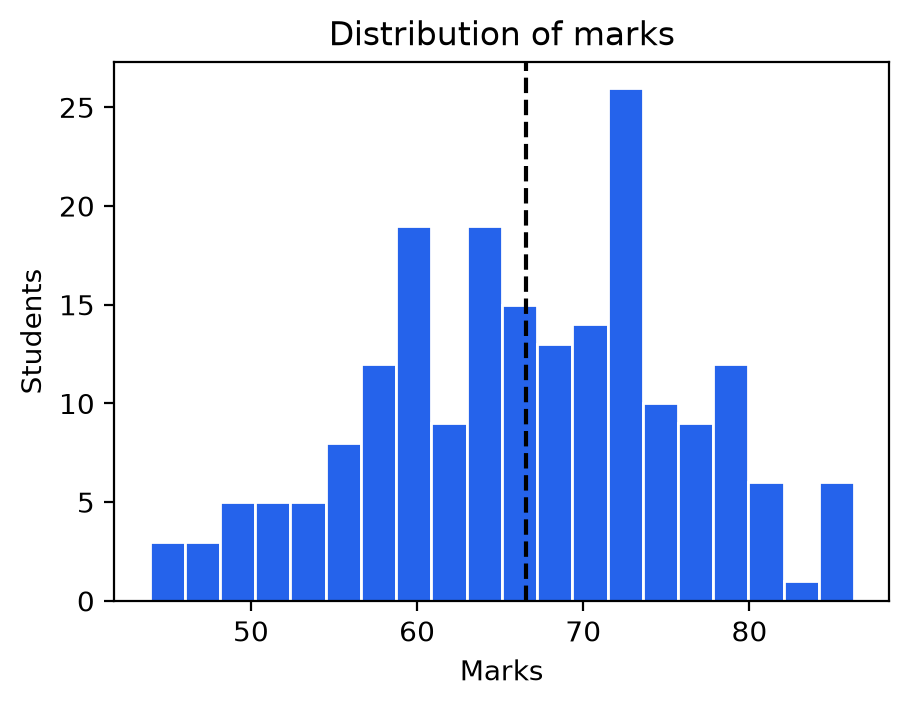

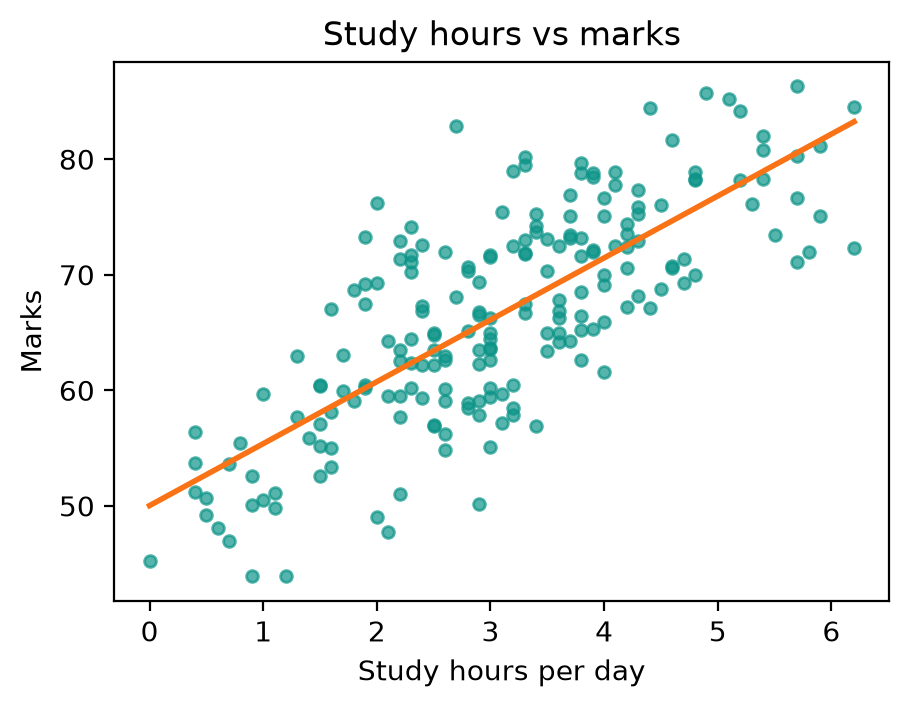

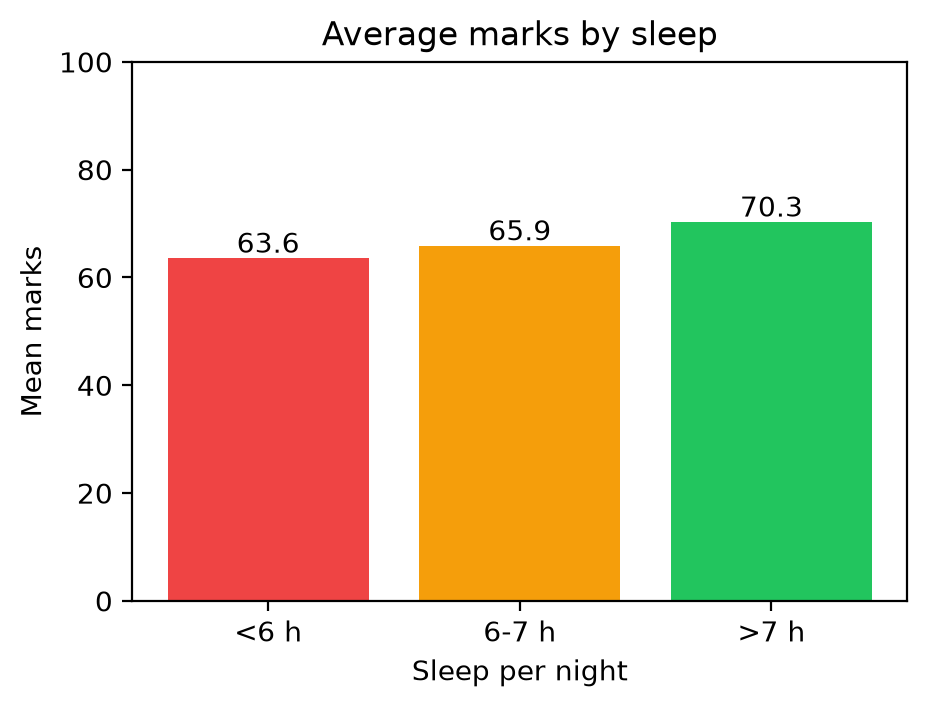

In [8]:
from IPython.display import Image, display
for f in ["img/f1.png", "img/f2.png", "img/f3.png"]:
    display(Image(f))